# Source Granularity

Strongest neighbors observed for an example section at different granularity levels.

## 0. Set Up

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


from network_pluralism.access.resolved import to_level
from network_pluralism.access.ego import get_ego_matrix
from network_pluralism.access.utils.labels import get_well_written_sections
from network_pluralism.setup.params import (
    DECISION_LEVEL_COLOR,
    PARAGRAPH_LEVEL_COLOR,
)
from network_pluralism.visualization.bar_plots import (
    show_perspectives_as_bars,
)


In [2]:
def set_rcParams(**kwargs):
    params = {
        "pdf.fonttype": 42,
        "text.usetex": True,
        "font.family": "serif",
        #"text.latex.preamble": r"\usepackage{amssymb}\usepackage{amsmath}\usepackage{amsfonts}\usepackage{lmodern}",
        "font.size": 12,
        "legend.fontsize": 14,
        "legend.title_fontsize": 16,
        "axes.labelsize": 12,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "axes.spines.right": False,
        "axes.spines.top": False,
        "legend.columnspacing": 1.0,
        "legend.frameon": False,
        "lines.linewidth": 3,
    }
    for param in kwargs:
        if param in plt.rcParams.keys():
            params[param] = kwargs[param]
    for k, v in params.items():
        plt.rcParams[k] = v


set_rcParams()

In [3]:
EXPORT_PATH = Path("../../figures_and_results/source_granularity")
EXPORT_PATH.mkdir(parents=True, exist_ok=True)

## 1. Computation

In [4]:
investigated_unit = "bgb_433"
n = 10  # number of top neighbors

### a) Data

In [5]:
matrix, rows_mapping, col_mapping = to_level(2, 1)  # 2 = Decision Level, 1 = Section level

Out Matrix of shape (74214, 93645)


In [6]:
ego_matrix_decision_level, indices_decision_level = get_ego_matrix(investigated_unit, d=2, s=1)
ego_matrix_para_level, indices_para_level = get_ego_matrix(investigated_unit, d=3, s=1)

Out Matrix of shape (74214, 93645)


Out Matrix of shape (74214, 93645)


Out Matrix of shape (74214, 93645)


Out Matrix of shape (3111483, 93645)


Out Matrix of shape (3111483, 93645)


Out Matrix of shape (3111483, 93645)


In [7]:
sem_id = investigated_unit

p1 = pd.DataFrame(
    ego_matrix_para_level[:, indices_para_level[sem_id]].toarray(), index=indices_para_level, columns=["count"]
).sort_values("count", ascending=False)
top_n_p1 = list(p1.head(n + 1).index)[1:]  # Removing self-cooccurrences
p1.drop(sem_id, inplace=True)

p2 = pd.DataFrame(
    ego_matrix_decision_level[:, indices_decision_level[sem_id]].toarray(),
    index=indices_decision_level,
    columns=["count"],
).sort_values("count", ascending=False)
top_n_p2 = list(p2.head(n + 1).index)[1:]
p2.drop(sem_id, inplace=True)

union_top_n = list(set(top_n_p1 + top_n_p2))
print(union_top_n)

merged_df = pd.merge(p1, p2)

['bgb_315', 'bgb_157', 'bgb_439', 'bgb_346', 'bgb_133', 'bgb_280', 'bgb_437', 'bgb_281', 'bgb_650', 'zpo_563', 'bgb_453', 'bgb_434', 'bgb_320', 'zpo_562', 'bgb_242']


In [8]:
# merge p1 and p2 on their index, keep all entries and add a difference column
merged_on_index = p1.merge(p2, left_index=True, right_index=True, how="outer", suffixes=("_para", "_dec"))
merged_on_index.fillna(0, inplace=True)

# Rescaling
merged_on_index["count_para_norm"] = merged_on_index["count_para"] / merged_on_index["count_para"].max()
merged_on_index["count_dec_norm"] = merged_on_index["count_dec"] / merged_on_index["count_dec"].max()

merged_on_index["diff"] = merged_on_index["count_dec_norm"] - merged_on_index["count_para_norm"]

final_df = merged_on_index.loc[union_top_n].sort_values("count_dec", ascending=False)
final_df

,count_para,count_dec,count_para_norm,count_dec_norm,diff
zpo_563,1.0,103.0,0.035714,1.000000,0.964286
zpo_562,1.0,88.0,0.035714,0.854369,0.818655
bgb_157,4.0,52.0,0.142857,0.504854,0.361997
bgb_133,4.0,51.0,0.142857,0.495146,0.352288
bgb_437,21.0,50.0,0.750000,0.485437,-0.264563
bgb_280,26.0,48.0,0.928571,0.466019,-0.462552
bgb_434,28.0,44.0,1.000000,0.427184,-0.572816
bgb_346,11.0,36.0,0.392857,0.349515,-0.043343
bgb_242,4.0,33.0,0.142857,0.320388,0.177531
bgb_315,10.0,32.0,0.357143,0.310680,-0.046463


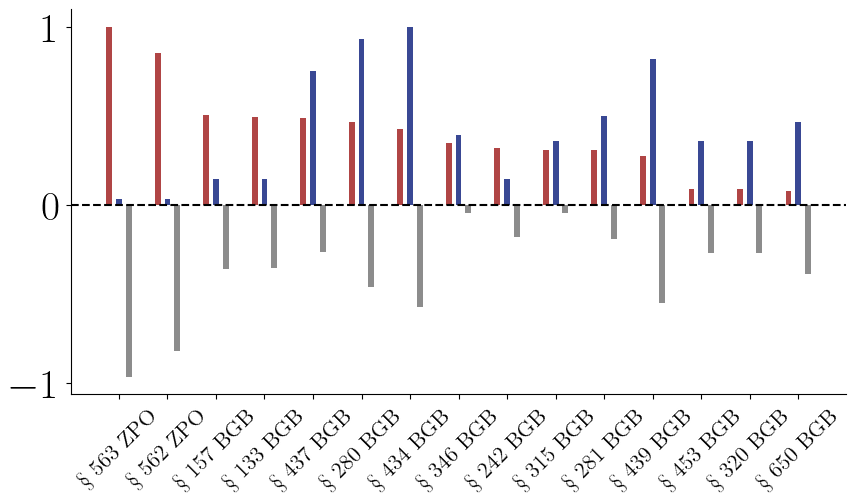

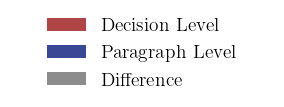

In [9]:
(EXPORT_PATH / investigated_unit).mkdir(exist_ok=True)
show_perspectives_as_bars(
    [
        final_df.count_dec_norm.to_list(),
        final_df.count_para_norm.to_list(),
        (-abs(final_df.count_para_norm - final_df.count_dec_norm)).to_list(),
    ],
    x_labels=list(get_well_written_sections(list(final_df.index)).values()),
    perspective_labels=["Decision Level", "Paragraph Level", "Difference"],
    rotation=45,
    legend_in_extra_plot=True,
    colors=[DECISION_LEVEL_COLOR, PARAGRAPH_LEVEL_COLOR, "grey"],
    fig_size=(10, 5),
    save_dir=EXPORT_PATH / investigated_unit,
    file_name="side_by_side.pdf",
    width=.12
)
